In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

# Agreement with analytical, constant temp, vary cycles

In [3]:
ns = [10, 100, 1000, 10000, 100000, 1000000, 10000000]

output = pd.DataFrame(columns=['iters', 'e', 'm', 'CV', 'Xi'])

for n in ns:
    #Read in file
    data = pd.read_csv(f'../Outputs/L2_T1_n{n}_analyticalcomparison.txt')

    #Compute quantities of interest
    exp_e = data['epsilon'].mean()
    exp_m = data[' abs(m)'].mean()
    data['epsilon squared'] = data['epsilon']*data['epsilon']
    data['mag squared'] = data[' abs(m)']*data[' abs(m)']
    CV = np.square(2)*(1/1)*(data['epsilon squared'].mean() - np.square(exp_e))
    Xi = np.square(2)*(1/1)*(data['mag squared'].mean() - np.square(exp_m))

    output = pd.concat([output, pd.DataFrame({'iters': [n], 'e': [exp_e], 'm': [exp_m], 'CV': [CV], 'Xi': [Xi]})], ignore_index=True)

C:\Users\bhaan\AppData\Local\Temp\ipykernel_7456\3054314964.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, pd.DataFrame({'iters': [n], 'e': [exp_e], 'm': [exp_m], 'CV': [CV], 'Xi': [Xi]})], ignore_index=True)


In [4]:
print(output)

      iters         e         m        CV        Xi
0        10 -1.800000  0.900000  1.440000  0.360000
1       100 -2.000000  1.000000  0.000000  0.000000
2      1000 -1.990000  0.996500  0.079600  0.010951
3     10000 -1.995000  0.998300  0.039900  0.005188
4    100000 -1.995760  0.998620  0.033848  0.004032
5   1000000 -1.995948  0.998638  0.032350  0.004113
6  10000000 -1.995967  0.998651  0.032204  0.004053


In [16]:
#Analytical

Lattice_factor = 1/4 #1/N
Temp_factor = 1/np.square(1) #1/(T^2)

a_exp_e = -Lattice_factor*(8*math.sinh(8))/(math.cosh(8)+3)
print(a_exp_e)
#Should be about -2

a_exp_m = Lattice_factor*(4 + 2*math.exp(8))/(math.cosh(8)+3)
print(a_exp_m)
#should be about 1

a_exp_CV = Lattice_factor*Temp_factor*(64 + 192*math.cosh(8))/(np.square(math.cosh(8)+3))
print(a_exp_CV)
#should be about 0.032

a_exp_Xi = Lattice_factor*Temp_factor*(8*math.cosh(8) + 8 + 8*math.exp(8)*math.cosh(8) + 8*math.exp(8) - 4*math.exp(16))/(np.square(math.cosh(8)+3))
print(a_exp_Xi)
#should be about 0.004

-1.99598208593669
0.9986607327485997
0.032082331864289666
0.00401073951622793


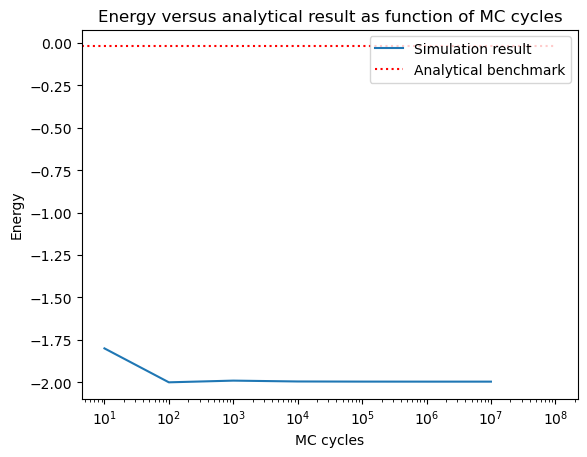

In [6]:
plt.plot(output['iters'], output['e'], label='Simulation result')
plt.hlines(a_exp_e, 0, 10e7, linestyles=':', colors='red', label='Analytical benchmark')
plt.xscale('log')
plt.xlabel('MC cycles')
plt.ylabel('Energy')
plt.title('Energy versus analytical result as function of MC cycles')
plt.legend()

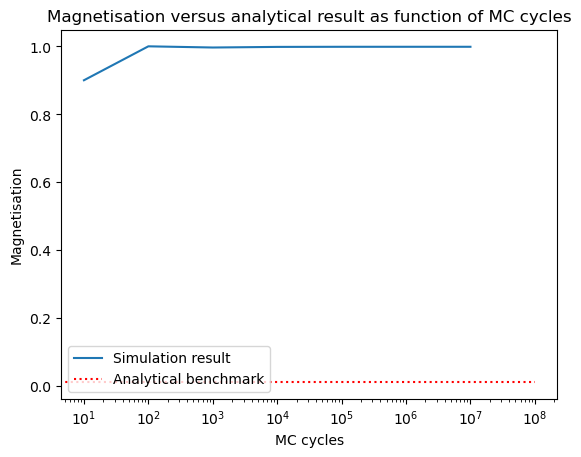

In [7]:
plt.plot(output['iters'], output['m'], label='Simulation result')
plt.hlines(a_exp_m, 0, 10e7, linestyles=':', colors='red', label='Analytical benchmark')
plt.xscale('log')
plt.xlabel('MC cycles')
plt.ylabel('Magnetisation')
plt.title('Magnetisation versus analytical result as function of MC cycles')
plt.legend()

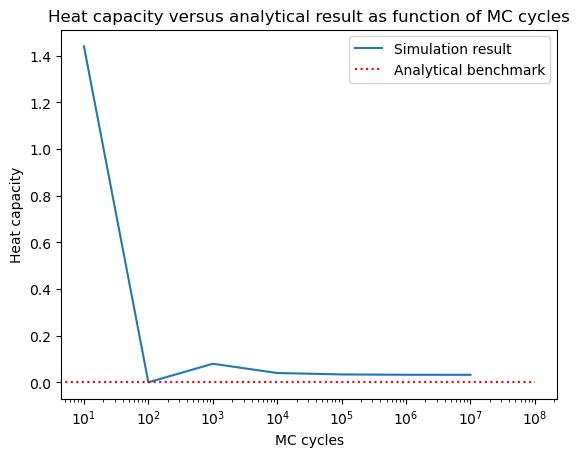

In [8]:
plt.plot(output['iters'], output['CV'], label='Simulation result')
plt.hlines(a_exp_CV, 0, 10e7, linestyles=':', colors='red', label='Analytical benchmark')
plt.xscale('log')
plt.xlabel('MC cycles')
plt.ylabel('Heat capacity')
plt.title('Heat capacity versus analytical result as function of MC cycles')
plt.legend()

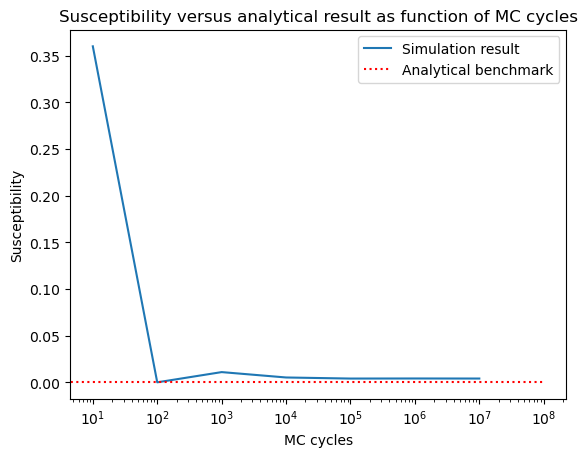

In [9]:
plt.plot(output['iters'], output['Xi'], label='Simulation result')
plt.hlines(a_exp_Xi, 0, 10e7, linestyles=':', colors='red', label='Analytical benchmark')
plt.xscale('log')
plt.xlabel('MC cycles')
plt.ylabel('Susceptibility')
plt.title('Susceptibility versus analytical result as function of MC cycles')
plt.legend()

# Agreement with analytical, 10e6 cycles, vary temp

In [10]:
temps = np.arange(1, 5, 0.1)

output = pd.DataFrame(columns=['temp', 'e', 'm', 'CV', 'Xi'])

for temp in temps:
    #Read in file
    temp = round(temp,1)
    data = pd.read_csv(f'../Outputs/L2_T{temp}00000_n10e5_analyticalcomparison.txt')

    Lattice_factor = 1/4 #1/N
    Temp_factor = 1/np.square(temp) #1/(T^2)

    #Compute quantities of interest
    exp_e = data['epsilon'].mean()
    exp_m = data[' abs(m)'].mean()
    data['epsilon squared'] = data['epsilon']*data['epsilon']
    data['mag squared'] = data[' abs(m)']*data[' abs(m)']
    CV = (1/Lattice_factor)*Temp_factor*(data['epsilon squared'].mean() - np.square(exp_e))
    Xi = (1/Lattice_factor)*np.sqrt(Temp_factor)*(data['mag squared'].mean() - np.square(exp_m))

    output = pd.concat([output, pd.DataFrame({'temp': [temp], 'e': [exp_e], 'm': [exp_m], 'CV': [CV], 'Xi': [Xi]})], ignore_index=True)


C:\Users\bhaan\AppData\Local\Temp\ipykernel_7456\1527766961.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, pd.DataFrame({'temp': [temp], 'e': [exp_e], 'm': [exp_m], 'CV': [CV], 'Xi': [Xi]})], ignore_index=True)


In [11]:
#Repeat the above, but instead make a df with the analytical solution
temps = np.arange(1, 5, 0.1)

ana = pd.DataFrame(columns=['temp', 'e', 'm', 'CV', 'Xi'])

for temp in temps:
    Lattice_factor = 1/4 #1/N
    Temp_factor = 1/np.square(temp) #1/(T^2)
    beta = 1/temp
    #Compute quantities of interest
    e = -Lattice_factor*(8*math.sinh(8*beta))/(math.cosh(8*beta)+3)
    m = Lattice_factor*(4 + 2*math.exp(8*beta))/(math.cosh(8*beta)+3)
    CV = Lattice_factor*Temp_factor*(64 + 192*math.cosh(8*beta))/(np.square(math.cosh(8*beta)+3))
    Xi = Lattice_factor*np.sqrt(Temp_factor)*(8*math.cosh(8*beta) + 8 + 8*math.exp(8*beta)*math.cosh(8*beta) + 8*math.exp(8*beta) - 4*math.exp(16*beta))/(np.square(math.cosh(8*beta)+3))

    ana = pd.concat([ana, pd.DataFrame({'temp': [temp], 'e': [e], 'm': [m], 'CV': [CV], 'Xi': [Xi]})], ignore_index=True)

C:\Users\bhaan\AppData\Local\Temp\ipykernel_7456\2591403901.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ana = pd.concat([ana, pd.DataFrame({'temp': [temp], 'e': [e], 'm': [m], 'CV': [CV], 'Xi': [Xi]})], ignore_index=True)


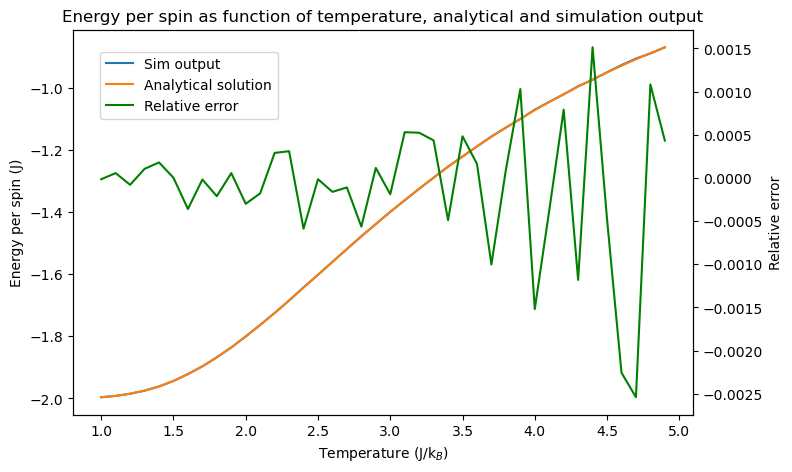

In [12]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(output['temp'], output['e'], label='Sim output')
ax1.plot(ana['temp'], ana['e'], label = 'Analytical solution')
ax1.set_xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel('Energy per spin (J)')

ax2 = ax1.twinx()
ax2.plot(output['temp'], (output['e']-ana['e'])/(ana['e']), c='green', label='Relative error')
ax2.set_ylabel('Relative error')
plt.title('Energy per spin as function of temperature, analytical and simulation output')
fig.legend(loc='upper left', bbox_to_anchor=(0.15, 0.85))

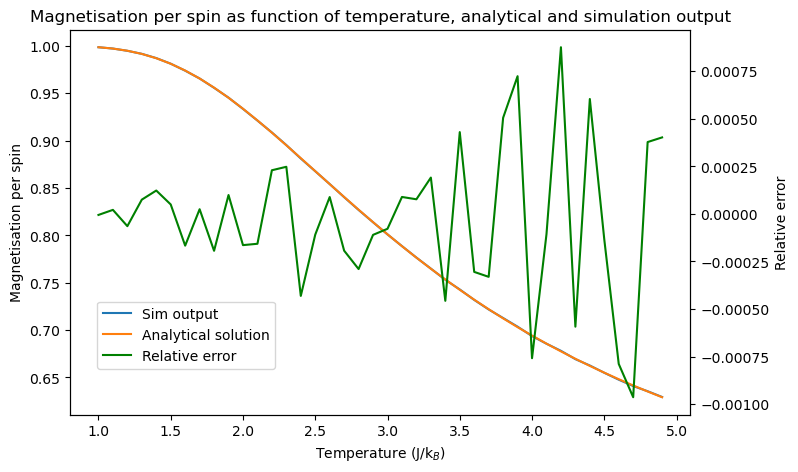

In [13]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(output['temp'], output['m'], label='Sim output')
ax1.plot(ana['temp'], ana['m'], label = 'Analytical solution')
ax1.set_xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel('Magnetisation per spin')

ax2 = ax1.twinx()
ax2.plot(output['temp'], (output['m']-ana['m'])/(ana['m']), c='green', label='Relative error')
ax2.set_ylabel('Relative error')
plt.title('Magnetisation per spin as function of temperature, analytical and simulation output')
fig.legend(loc='upper left', bbox_to_anchor=(0.15, 0.35))

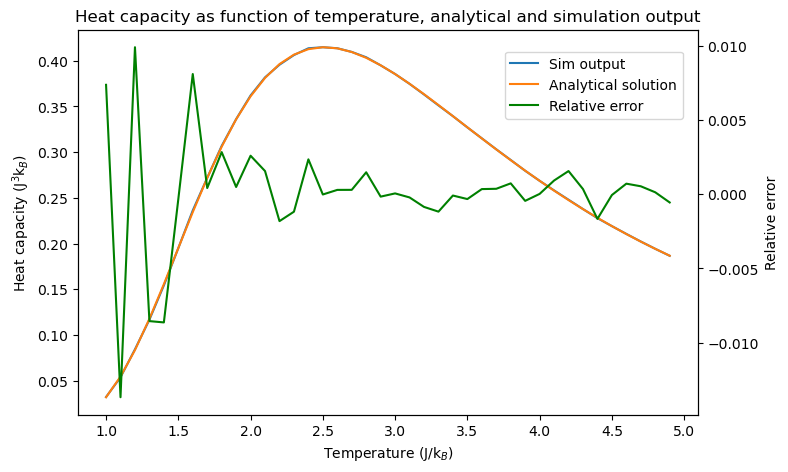

In [14]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(output['temp'], output['CV'], label='Sim output')
ax1.plot(ana['temp'], ana['CV'], label = 'Analytical solution')
ax1.set_xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel(r'Heat capacity (J$^3$k$_B$)')

ax2 = ax1.twinx()
ax2.plot(output['temp'], (output['CV']-ana['CV'])/(ana['CV']), c='green', label='Relative error')
ax2.set_ylabel('Relative error')
plt.title('Heat capacity as function of temperature, analytical and simulation output')
fig.legend(loc='upper left', bbox_to_anchor=(0.65, 0.85))

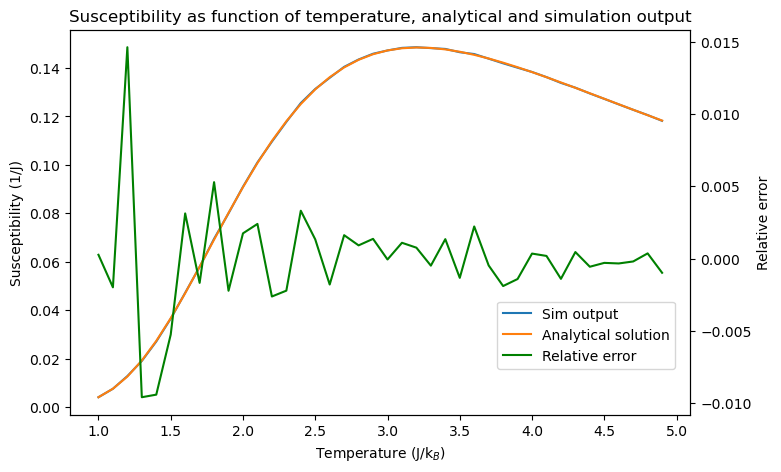

In [15]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(output['temp'], output['Xi'], label='Sim output')
ax1.plot(ana['temp'], ana['Xi'], label = 'Analytical solution')
ax1.set_xlabel(r'Temperature (J/k$_B$)')
ax1.set_ylabel('Susceptibility (1/J)')

ax2 = ax1.twinx()
ax2.plot(output['temp'], (output['Xi']-ana['Xi'])/(ana['Xi']), c='green', label='Relative error')
ax2.set_ylabel('Relative error')
plt.title('Susceptibility as function of temperature, analytical and simulation output')
fig.legend(loc='upper left', bbox_to_anchor=(0.65, 0.35))